In [1]:
import os, numpy as np, pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

ROOT = Path("/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations")
articles = pd.read_csv(ROOT / "articles.csv")
print(articles.shape)
print(articles.columns.tolist())

(105542, 25)
['article_id', 'product_code', 'prod_name', 'product_type_no', 'product_type_name', 'product_group_name', 'graphical_appearance_no', 'graphical_appearance_name', 'colour_group_code', 'colour_group_name', 'perceived_colour_value_id', 'perceived_colour_value_name', 'perceived_colour_master_id', 'perceived_colour_master_name', 'department_no', 'department_name', 'index_code', 'index_name', 'index_group_no', 'index_group_name', 'section_no', 'section_name', 'garment_group_no', 'garment_group_name', 'detail_desc']


In [2]:
import torch
print(torch.cuda.is_available(), torch.cuda.device_count())

True 2


In [3]:
tx = pd.read_csv(
    ROOT / "transactions_train.csv",
    usecols=["t_dat", "article_id"],
    dtype={"article_id": "int32"},
    parse_dates=["t_dat"],
)
tx["wk"] = ((tx.t_dat - tx.t_dat.min()).dt.days // 7).astype("int16")
n_wk = int(tx.wk.max()) + 1
print(len(tx), "rows,", n_wk, "weeks")

31788324 rows, 105 weeks


In [4]:
tx

,t_dat,article_id,wk
0,2018-09-20,663713001,0
1,2018-09-20,541518023,0
2,2018-09-20,505221004,0
3,2018-09-20,685687003,0
4,2018-09-20,685687004,0
...,...,...,...
31788319,2020-09-22,929511001,104
31788320,2020-09-22,891322004,104
31788321,2020-09-22,918325001,104
31788322,2020-09-22,833459002,104


In [5]:
g = tx.groupby("article_id")["wk"].agg(first_wk="min", last_wk="max", active="nunique", total="size")
g["span"] = g.last_wk - g.first_wk

In [6]:
rows = []
for span_max in [16, 20, 26, 32]:
    for tot_min in [30, 60, 100]:
        f = (g.first_wk >= 4) & (g.span <= span_max) & (g.last_wk < n_wk - 8) & (g.total >= tot_min)
        rows.append((span_max, tot_min, int(f.sum())))
print(pd.DataFrame(rows, columns=["span_max", "total_min", "n_trend"]).pivot(index="span_max", columns="total_min", values="n_trend"))

total_min   30    60    100
span_max                   
16         2219   974   469
20         3572  1783   996
26         5869  3386  2143
32         8032  4965  3356


In [7]:
SPAN_MAX, TOT_MIN = 20, 60   # the values we settled on (1,783 trend pieces)

# Staple: sold for a long time, still selling at the end of the data
staple = (g.span >= 80) & (g.active >= 60) & (g.total >= 500) & (g.last_wk >= n_wk - 4)

# Trend piece: launched inside the window, short life, finished before the last 8 weeks
fad = (g.first_wk >= 4) & (g.span <= SPAN_MAX) & (g.last_wk < n_wk - 8) & (g.total >= TOT_MIN)

g["label"] = np.nan
g.loc[staple, "label"] = 0
g.loc[fad, "label"] = 1
lab = g.dropna(subset=["label"]).copy()
lab["label"] = lab.label.astype(int)

meta = articles.set_index("article_id")[["product_code", "product_type_name", "colour_group_name", "detail_desc"]]
lab = lab.join(meta)
print(lab.label.value_counts())
print(lab.groupby("label")[["span", "active", "total"]].median())

label
0    1788
1    1783
Name: count, dtype: int64
        span  active   total
label                       
0      102.0    89.0  1636.0
1       16.0    14.0   107.0


In [8]:
import os
IMG = "/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations/images"
lab = lab.reset_index()
lab["aid"] = lab.article_id.astype(str).str.zfill(10)
lab["path"] = IMG + "/" + lab.aid.str[:3] + "/" + lab.aid + ".jpg"
lab = lab[lab.path.apply(os.path.exists)]
print(lab.label.value_counts())

N = min(lab.label.value_counts().min(), 4000)
data = pd.concat([lab[lab.label == k].sample(N, random_state=0) for k in (0, 1)]).reset_index(drop=True)
print(data.label.value_counts())

label
1    1783
0    1774
Name: count, dtype: int64
label
0    1774
1    1774
Name: count, dtype: int64


In [9]:
from sentence_transformers import SentenceTransformer
from PIL import Image
clip = SentenceTransformer("clip-ViT-L-14", device="cuda")

modules.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/118 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

0_CLIPModel/model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/733 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [10]:
embs = []
for i in range(0, len(data), 64):
    imgs = [Image.open(p).convert("RGB") for p in data.path[i:i+64]]
    embs.append(clip.encode(imgs, batch_size=64, normalize_embeddings=True))
X = np.vstack(embs)
np.save("/kaggle/working/X.npy", X)
data.to_csv("/kaggle/working/data.csv", index=False)
print(X.shape)

(3548, 768)


In [11]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, f1_score
from xgboost import XGBClassifier

y = data.label.values
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
tr, te = next(gss.split(X, y, groups=data.product_code))

# Baseline: product type only
ohe = OneHotEncoder(handle_unknown="ignore")
Btr = ohe.fit_transform(data.loc[tr, ["product_type_name"]])
Bte = ohe.transform(data.loc[te, ["product_type_name"]])
base = LogisticRegression(max_iter=1000).fit(Btr, y[tr])
p_base = base.predict_proba(Bte)[:, 1]

lr = LogisticRegression(max_iter=2000, C=1.0).fit(X[tr], y[tr])
p_lr = lr.predict_proba(X[te])[:, 1]

xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.5, eval_metric="logloss")
xgb.fit(X[tr], y[tr])
p_xgb = xgb.predict_proba(X[te])[:, 1]

for name, p in [("Baseline (type)", p_base), ("CLIP + LR", p_lr), ("CLIP + XGB", p_xgb)]:
    print(f"{name:16s} AUC {roc_auc_score(y[te], p):.3f}  F1 {f1_score(y[te], p > 0.5):.3f}")
print("Lift over baseline (LR):", round(roc_auc_score(y[te], p_lr) - roc_auc_score(y[te], p_base), 3))

Baseline (type)  AUC 0.731  F1 0.715
CLIP + LR        AUC 0.853  F1 0.760
CLIP + XGB       AUC 0.873  F1 0.788
Lift over baseline (LR): 0.122


In [12]:
p_ens = (p_lr + p_xgb) / 2

for name, p in [("CLIP + LR", p_lr), ("CLIP + XGB", p_xgb), ("Ensemble (LR+XGB)", p_ens)]:
    print(f"{name:18s} AUC {roc_auc_score(y[te], p):.3f}  F1 {f1_score(y[te], p > 0.5):.3f}")
print("Lift over baseline (ensemble):", round(roc_auc_score(y[te], p_ens) - roc_auc_score(y[te], p_base), 3))

CLIP + LR          AUC 0.853  F1 0.760
CLIP + XGB         AUC 0.873  F1 0.788
Ensemble (LR+XGB)  AUC 0.870  F1 0.787
Lift over baseline (ensemble): 0.139


In [13]:
d = data.copy()
d["lt"] = np.log10(d.total)
d["bin"] = pd.qcut(d['lt'], 10, duplicates="drop")

In [14]:
lo, hi = 200, 1000
band = data[(data.total >= lo) & (data.total <= hi)]
print(band.label.value_counts())

aucs, sizes = [], []
for seed in range(20):
    n = band.label.value_counts().min()
    b = pd.concat([band[band.label == k].sample(n, random_state=seed) for k in (0, 1)])
    idx = b.index.values
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed)
    a, c = next(gss2.split(idx, y[idx], groups=data.product_code.values[idx]))
    m2 = LogisticRegression(max_iter=2000).fit(X[idx[a]], y[idx[a]])
    aucs.append(roc_auc_score(y[idx[c]], m2.predict_proba(X[idx[c]])[:, 1]))
    sizes.append(len(idx))
print(f"Volume-band CLIP+LR AUC: {np.mean(aucs):.3f} +/- {np.std(aucs):.3f} (n per run ~{int(np.mean(sizes))}, 20 seeds)")

label
0    525
1    365
Name: count, dtype: int64
Volume-band CLIP+LR AUC: 0.788 +/- 0.031 (n per run ~730, 20 seeds)


In [15]:
te_df = data.loc[te].copy()
te_df["p"] = p_lr
rows = []
for t, grp in te_df.groupby("product_type_name"):
    if len(grp) >= 40 and grp.label.nunique() == 2:
        rows.append((t, len(grp), roc_auc_score(grp.label, grp.p)))
print(pd.DataFrame(rows, columns=["type", "n", "auc"]).sort_values("auc", ascending=False).to_string(index=False))

    type   n      auc
Trousers 111 0.899875
   Dress  55 0.896396
 T-shirt  64 0.860119
 Sweater  80 0.730957


In [16]:
rng = np.random.default_rng(0)
rows = []
for t, grp in te_df.groupby("product_type_name"):
    if len(grp) >= 25 and grp.label.nunique() == 2:
        y_t, p_t = grp.label.values, grp.p.values
        boots = []
        for _ in range(500):
            i = rng.integers(0, len(grp), len(grp))
            if len(set(y_t[i])) == 2:
                boots.append(roc_auc_score(y_t[i], p_t[i]))
        rows.append((t, len(grp), roc_auc_score(y_t, p_t), np.percentile(boots, 2.5), np.percentile(boots, 97.5)))
print(pd.DataFrame(rows, columns=["type", "n", "auc", "lo95", "hi95"]).sort_values("auc", ascending=False).round(3).to_string(index=False))

            type   n   auc  lo95  hi95
Underwear bottom  32 0.953 0.872 1.000
         Earring  30 0.905 0.758 1.000
        Trousers 111 0.900 0.799 0.979
           Dress  55 0.896 0.791 0.962
         T-shirt  64 0.860 0.770 0.937
           Shirt  28 0.854 0.688 0.969
 Swimwear bottom  30 0.786 0.483 1.000
          Shorts  30 0.736 0.538 0.911
         Sweater  80 0.731 0.606 0.832
          Blouse  37 0.694 0.487 0.857
             Top  34 0.575 0.353 0.783


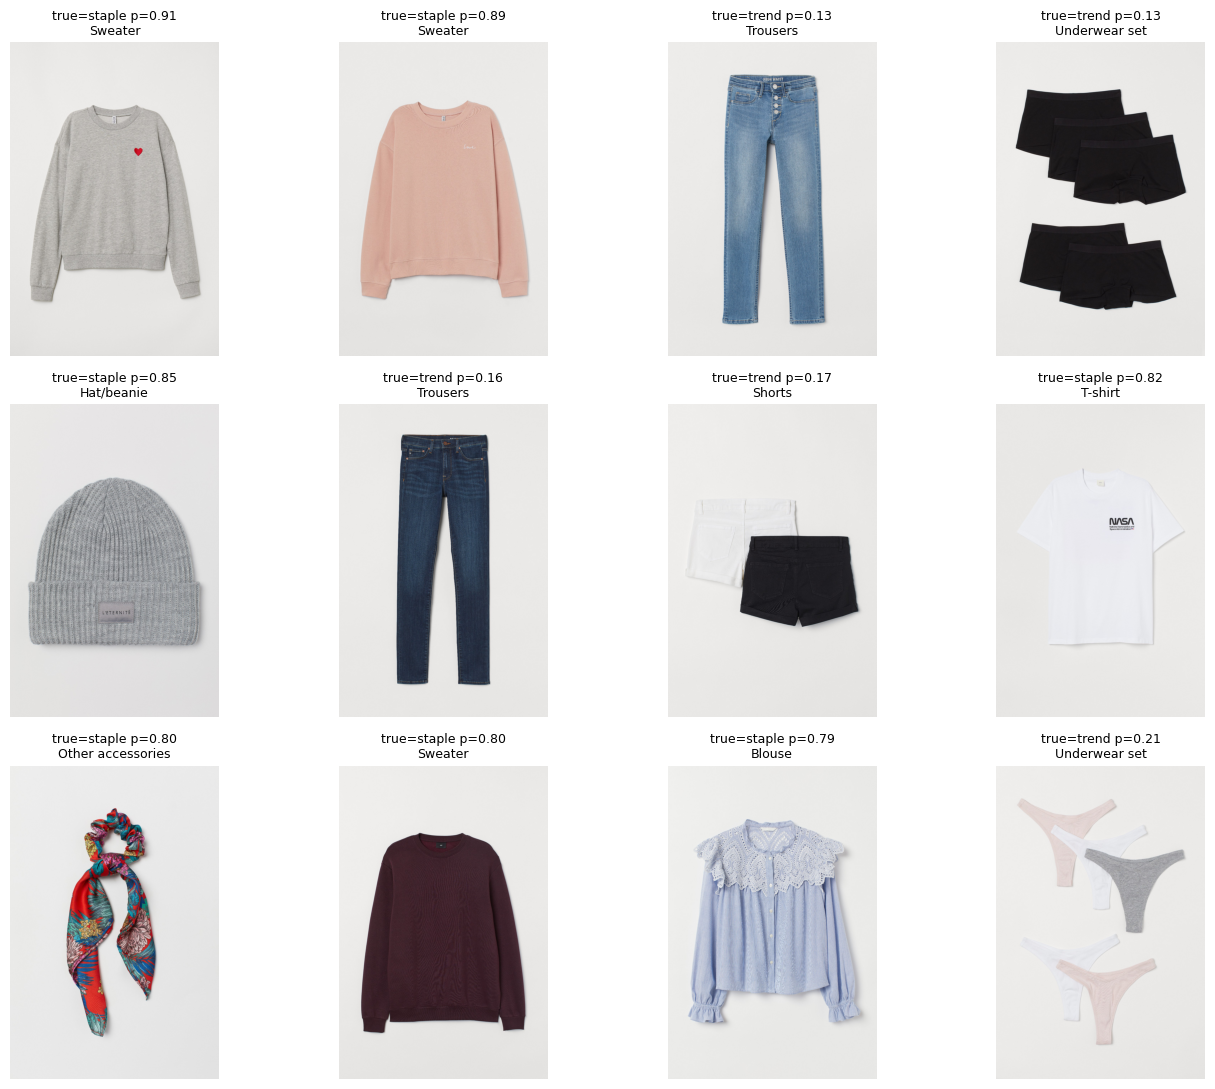

In [17]:
import matplotlib.pyplot as plt
te_df["wrong"] = (te_df.p > 0.5) != (te_df.label == 1)
te_df["conf"] = (te_df.p - 0.5).abs()
bad = te_df[te_df.wrong].sort_values("conf", ascending=False).head(12)

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, (_, r) in zip(axes.ravel(), bad.iterrows()):
    ax.imshow(Image.open(r.path)); ax.axis("off")
    ax.set_title(f"true={'trend' if r.label else 'staple'} p={r.p:.2f}\n{r.product_type_name}", fontsize=9)
plt.tight_layout(); plt.show()

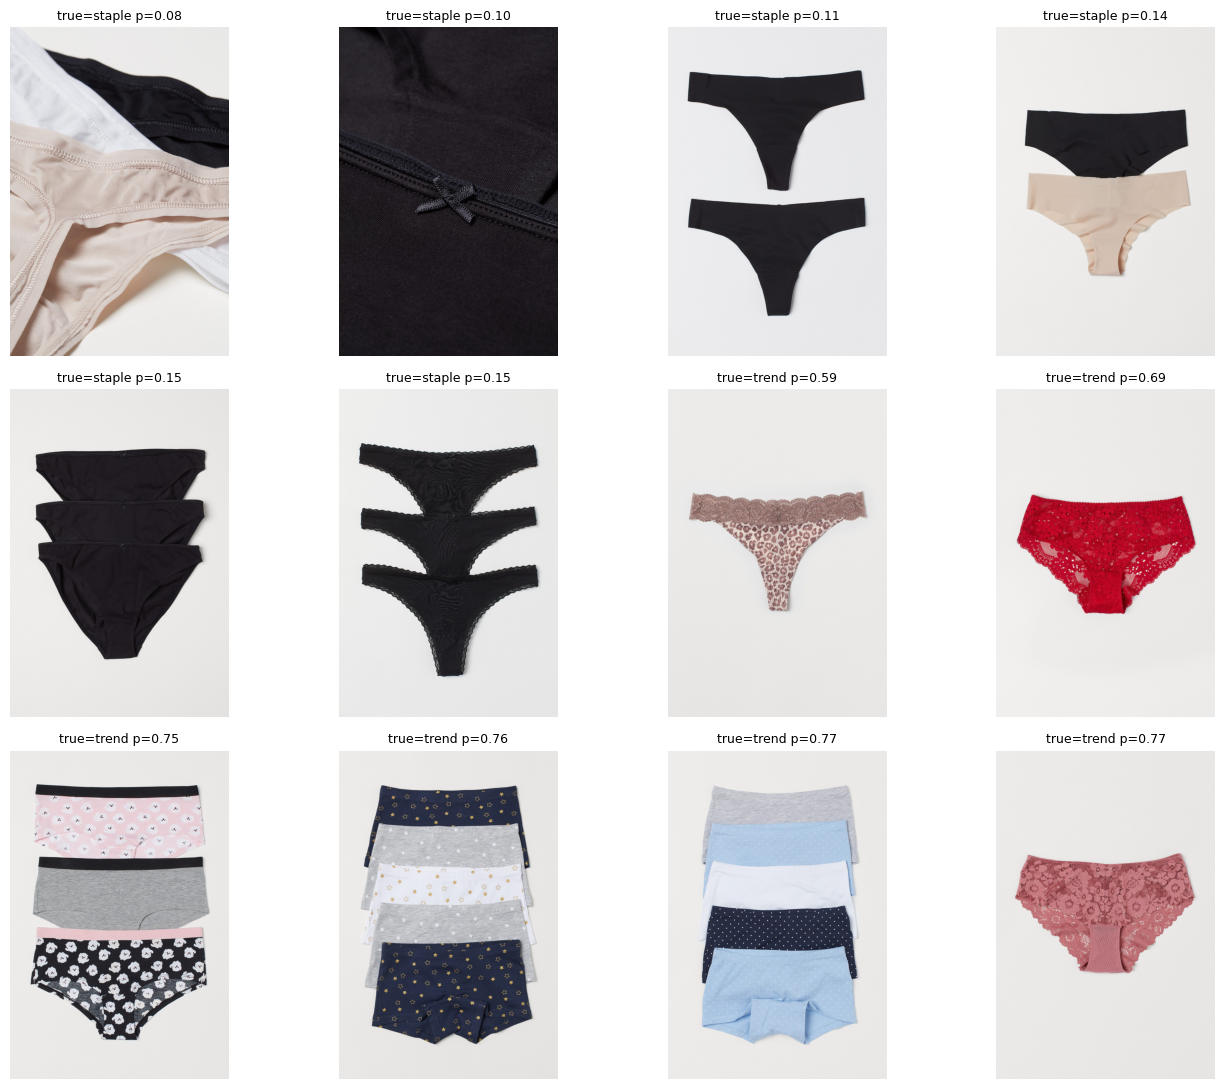

In [18]:
u = te_df[te_df.product_type_name == "Underwear bottom"].sort_values("p")
show = pd.concat([u.head(6), u.tail(6)])
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, (_, r) in zip(axes.ravel(), show.iterrows()):
    ax.imshow(Image.open(r.path)); ax.axis("off")
    ax.set_title(f"true={'trend' if r.label else 'staple'} p={r.p:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

In [19]:
from sklearn.model_selection import StratifiedGroupKFold

skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
res = {k: {"auc": [], "f1": []} for k in ["Baseline (type)", "CLIP + LR", "CLIP + XGB", "Ensemble"]}

for f, (a, c) in enumerate(skf.split(X, y, groups=data.product_code)):
    ohe = OneHotEncoder(handle_unknown="ignore")
    Ba = ohe.fit_transform(data.loc[a, ["product_type_name"]])
    Bc = ohe.transform(data.loc[c, ["product_type_name"]])
    pb = LogisticRegression(max_iter=1000).fit(Ba, y[a]).predict_proba(Bc)[:, 1]

    pl = LogisticRegression(max_iter=2000).fit(X[a], y[a]).predict_proba(X[c])[:, 1]
    px = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                       subsample=0.8, colsample_bytree=0.5, eval_metric="logloss"
                       ).fit(X[a], y[a]).predict_proba(X[c])[:, 1]
    for k, p in [("Baseline (type)", pb), ("CLIP + LR", pl), ("CLIP + XGB", px), ("Ensemble", (pl + px) / 2)]:
        res[k]["auc"].append(roc_auc_score(y[c], p))
        res[k]["f1"].append(f1_score(y[c], p > 0.5))

for k, v in res.items():
    print(f"{k:16s} AUC {np.mean(v['auc']):.3f} +/- {np.std(v['auc']):.3f}   F1 {np.mean(v['f1']):.3f} +/- {np.std(v['f1']):.3f}")
print("CV lift over baseline (XGB):", round(np.mean(res["CLIP + XGB"]["auc"]) - np.mean(res["Baseline (type)"]["auc"]), 3))

Baseline (type)  AUC 0.731 +/- 0.018   F1 0.687 +/- 0.029
CLIP + LR        AUC 0.870 +/- 0.007   F1 0.791 +/- 0.011
CLIP + XGB       AUC 0.892 +/- 0.011   F1 0.821 +/- 0.018
Ensemble         AUC 0.889 +/- 0.009   F1 0.816 +/- 0.014
CV lift over baseline (XGB): 0.16


In [20]:
oof = np.zeros(len(data))
for a, c in skf.split(X, y, groups=data.product_code):
    m = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.5, eval_metric="logloss").fit(X[a], y[a])
    oof[c] = m.predict_proba(X[c])[:, 1]
print("Pooled OOF AUC:", round(roc_auc_score(y, oof), 3))

oof_df = data.copy()
oof_df["p"] = oof
rng = np.random.default_rng(0)
rows = []
for t, grp in oof_df.groupby("product_type_name"):
    if len(grp) >= 40 and grp.label.nunique() == 2:
        yt, pt = grp.label.values, grp.p.values
        boots = []
        for _ in range(1000):
            i = rng.integers(0, len(grp), len(grp))
            if len(set(yt[i])) == 2:
                boots.append(roc_auc_score(yt[i], pt[i]))
        rows.append((t, len(grp), roc_auc_score(yt, pt), np.percentile(boots, 2.5), np.percentile(boots, 97.5)))
print(pd.DataFrame(rows, columns=["type", "n", "auc", "lo95", "hi95"]).sort_values("auc", ascending=False).round(3).to_string(index=False))

Pooled OOF AUC: 0.891
             type   n   auc  lo95  hi95
  Swimwear bottom  75 0.979 0.942 1.000
       Pyjama set  41 0.949 0.825 1.000
          Earring  81 0.923 0.835 0.983
          T-shirt 240 0.911 0.872 0.948
            Shirt 125 0.901 0.848 0.946
             Belt  41 0.899 0.786 0.983
            Skirt  57 0.890 0.799 0.959
              Bag  50 0.889 0.783 0.970
           Jacket  79 0.888 0.810 0.950
            Socks  77 0.887 0.790 0.961
           Hoodie  71 0.885 0.795 0.950
         Trousers 464 0.884 0.846 0.917
  Leggings/Tights  77 0.877 0.788 0.953
         Vest top  85 0.871 0.788 0.945
           Shorts 106 0.859 0.781 0.930
           Blazer  41 0.842 0.696 0.958
          Sweater 314 0.841 0.790 0.888
 Underwear bottom 122 0.840 0.769 0.908
            Dress 240 0.835 0.777 0.886
              Top 130 0.835 0.761 0.906
              Bra 100 0.819 0.695 0.920
           Blouse 146 0.812 0.743 0.878
Other accessories  54 0.726 0.498 0.918
         Cardigan 

In [21]:
import gradio as gr

def predict(img):
    e = clip.encode([img.convert("RGB")], normalize_embeddings=True)
    p = float(xgb.predict_proba(e)[0, 1])
    return {"Trend piece": p, "Staple": 1 - p}

# Held-out candidates for the video (none of these were trained on)
cand = data.loc[te].copy()
cand["p"] = p_xgb
cand["ok"] = (cand.p > 0.5) == (cand.label == 1)
cols = ["path", "product_type_name", "label", "p"]
print("Correct staples:\n", cand[cand.ok & (cand.label == 0)].sort_values("p").head(6)[cols].to_string())
print("Correct trend:\n", cand[cand.ok & (cand.label == 1)].sort_values("p").tail(6)[cols].to_string())
print("Confident errors:\n", cand[~cand.ok].assign(c=lambda d: (d.p - 0.5).abs()).sort_values("c").tail(6)[cols].to_string())

gr.Interface(fn=predict, inputs=gr.Image(type="pil"), outputs=gr.Label(num_top_classes=2),
             title="Staple or trend piece?",
             description="Predicts from a photo whether a garment is a lasting staple or a short-lived trend piece. Labels come from H&M sales lifecycles."
            ).launch(share=True)

Correct staples:
                                                                                                    path product_type_name  label         p
1665  /kaggle/input/competitions/h-and-m-personalized-fashion-recommendations/images/072/0723347001.jpg        Bikini top      0  0.004716
1511  /kaggle/input/competitions/h-and-m-personalized-fashion-recommendations/images/058/0589222001.jpg          Trousers      0  0.005150
280   /kaggle/input/competitions/h-and-m-personalized-fashion-recommendations/images/039/0397068012.jpg          Trousers      0  0.006374
417   /kaggle/input/competitions/h-and-m-personalized-fashion-recommendations/images/039/0399087010.jpg          Trousers      0  0.006812
460   /kaggle/input/competitions/h-and-m-personalized-fashion-recommendations/images/061/0615939001.jpg        Bikini top      0  0.006962
933   /kaggle/input/competitions/h-and-m-personalized-fashion-recommendations/images/039/0399087029.jpg          Trousers      0  0.007393
Correct t